## Trying to perform AZURE2 fit using Brick

Using a working example such as 12C(p,p)

In [13]:
import pyphysics as phys
import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, List, Tuple, Optional, Literal
import pandas as pd

from brick.azr import AZR
from brick.output import Output

Build `ChiSquareMinimizer`class and `Parameter` class

In [30]:
azr = AZR("./Inputs/in_three.azr")

# Get parameters
nd = azr.config.nd
pars: List[phys.Parameter] = []
for i in range(nd):
    name = azr.config.labels[i]
    init_value = azr.config.get_input_values()[i]
    par = phys.Parameter(name=name, value=init_value)
    par.set_auto_bounds()
    if "Gamma" in par.name:
        par.lower = 0
        par.upper = 1e6
    pars.append(par)

# Set bounds
for p in pars:
    if "E_(1/2+)" in p.name:
        p.lower = 0.4
        p.upper = 0.6
    if "E_(5/2+)_1_1" in p.name:
        p.lower = -0.1
        p.upper = 0.2
    if "E_(3/2+)" in p.name:
        p.lower = 1.4
        p.upper = 1.8
    if "Gamma_(3/2+)" in p.name:
        p.lower = 1e3
        p.upper = 1e6
    print(p)

minimizer = phys.Chi2Minimizer(azr, pars, n_workers=1)
minimizer.fit()
# minimizer.summary()

E_(1/2+)_1_1 = 0.45 in [0.4, 0.6]
Gamma_(1/2+)_1_1 = 67000.0 in [0, 1000000.0]
E_(3/2+)_1_1 = 1.4 in [1.4, 1.8]
Gamma_(3/2+)_1_1 = 100.0 in [1000.0, 1000000.0]
n_1 = 1.0 in [1e-08, 100000000.0]
[[Fit Statistics]]
    # fitting method   = least_squares
    # function evals   = 101
    # data points      = 35
    # variables        = 5
    chi-square         = 73.9705716
    reduced chi-square = 2.46568572
    Akaike info crit   = 36.1911745
    Bayesian info crit = 43.9679148
[[Variables]]
    E_1_2p_1_1:      0.46970606 +/- 0.03694080 (7.86%) (init = 0.45)
    Gamma_1_2p_1_1:  642740.497 +/- 171689.354 (26.71%) (init = 67000)
    E_3_2p_1_1:      1.41425266 +/- 0.01307338 (0.92%) (init = 1.4)
    Gamma_3_2p_1_1:  29732.8975 +/- 12584.8769 (42.33%) (init = 1000)
    n_1:             0.00247222 +/- 1.6493e-04 (6.67%) (init = 1)
[[Correlations]] (unreported correlations are < 0.100)
    C(E_1_2p_1_1, Gamma_1_2p_1_1)     = -0.8121
    C(Gamma_1_2p_1_1, n_1)            = +0.7770
    C(E_1_2

Text(0, 0.5, '$\\sigma$ [mb]')

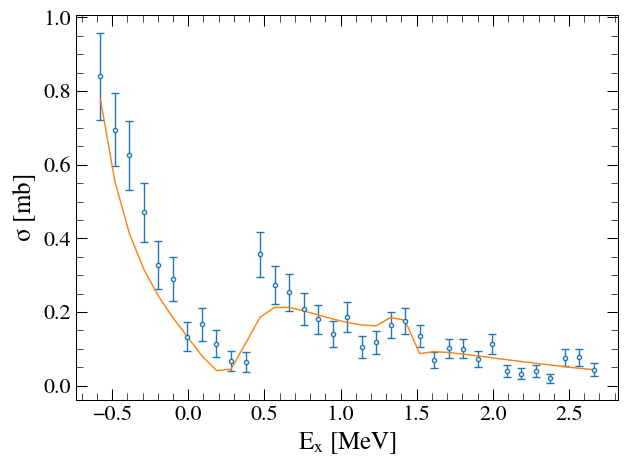

In [31]:
fig, ax = plt.subplots()

# Get best fit
best = minimizer.get_best_fit()
assert best is not None, "Results is None"
# Get data
x = best.e_x
y = best.xs_com_data
uy = best.xs_err_com_data
fit = best.xs_com_fit
ax.errorbar(x, y, yerr=uy, ls="none", marker="o", ms=3)
ax.plot(x, fit)

# Axis settings
ax.set_xlabel(r"$E_{x}$ [MeV]")
ax.set_ylabel(r"$\sigma$ [mb]")

